# Notebook 2: Explainable AI (XAI) -- LIME on text data

## Course: Big Data Analytics
## University of Milano-Bicocca
## Degree Programme: Economics, Data Analysis and Management

---

### Introduction

A model can have a great accuracy and still be **right for the wrong reasons**. In this notebook we:

1. **train** a black-box model that routes **medical documents** to the right department (Part 1);
2. **open** it with **LIME**, *Local Interpretable Model-agnostic Explanations*: first **by hand**, then with the library (Part 2);
3. **use** what LIME shows us to **find and fix** a hidden shortcut (Part 3).

> 📚 **The series**: 1. LIME · tabular → **2. LIME · text** (this notebook) → 3. SHAP · tabular → 4. SHAP · text. Notebooks 2 and 4 explain **the same text model**: same data, same training, only the explainer changes.

# IMAGINE: AN ALGORITHM SENDS YOUR MEDICAL RECORDS TO THE WRONG DEPARTMENT. HOW WOULD YOU FIND OUT WHICH WORDS MISLED IT?

---

## Why do we need explanations?

A text classifier with thousands of word weights is a **black box**: we see the input and the output, not the reasoning. In sensitive domains this is not enough:

- 🏥 **Health**: a clinician must be able to check *why* a system suggests something before acting on it.
- 🐛 **Shortcuts**: a model can exploit patterns that work on the test set but fail in the real world, and the accuracy will not tell you.
- 🔍 **Trust**: an explanation lets a domain expert say *"yes, these are the right reasons"*.

> **Global** explanations describe the whole model; **local** explanations answer the question *"why THIS prediction?"*. LIME is a **local** method.

In [ ]:
# ==========================================
# 1. SETUP: INSTALL AND IMPORT
# ==========================================

# LIME is not pre-installed on Colab: we install it with pip ("!" runs a shell command)
!pip install lime --quiet

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

from lime.lime_text import LimeTextExplainer          # LIME for text

warnings.filterwarnings("ignore")    # keep the output clean
np.random.seed(42)                   # reproducibility

# Colors of our own charts (colorblind-safe palette)
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#898781"
INK, GRID = "#52514e", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 150)

def dumbbell(table, xlabel, title, fmt="{:.1%}"):
    # Helper for "before vs after" charts: one row per item, columns = [before, after]
    before, after = table.columns
    fig, ax = plt.subplots(figsize=(8, 1.2 + 0.55 * len(table)))
    for i, (a, b) in enumerate(table.values):
        ax.plot([a, b], [i, i], color="#c3c2b7", lw=2, zorder=1)
        ax.scatter(a, i, s=110, color=GRAY, edgecolors="white", lw=2, zorder=2, label=before if i == 0 else None)
        ax.scatter(b, i, s=110, color=BLUE, edgecolors="white", lw=2, zorder=3, label=after if i == 0 else None)
        ax.annotate(fmt.format(a), (a, i), xytext=(0, 8), textcoords="offset points", ha="center", color=INK, fontsize=8)
        ax.annotate(fmt.format(b), (b, i), xytext=(0, -15), textcoords="offset points", ha="center", color=INK, fontsize=8)
    ax.set_yticks(range(len(table)), table.index)
    ax.set_ylim(-0.7, len(table) - 0.3)
    ax.set_xlabel(xlabel)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt.format(v)))
    ax.set_title(title, loc="left", pad=26)
    ax.xaxis.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
    plt.tight_layout()
    plt.show()

def show_lime(explanation, **kwargs):
    # Same as explanation.show_in_notebook(), but works with every IPython version
    display(HTML(explanation.as_html(**kwargs)))

print("✅ Setup complete")

# 🏗️ Part 1 — Train the black box

This is the **training** of the text model. **Notebook 4** (SHAP) repeats exactly this part (same data, same random seeds), so it explains **the identical model**.

## 1.1 🏥 The data: medical documents

The **Medical Abstracts** corpus (Schopf et al., 2023) contains abstracts of medical articles labelled by disease area. We keep two areas and treat them as **hospital departments**: *neoplasms* → **Oncology**, *cardiovascular diseases* → **Cardiology**. To keep the explanations readable (and fast) we keep only the **first 30 words** of each abstract (≈ title + first sentence).

### 🧪 A realistic twist (simulated)

Our hospital group has two sites: **Milan**, the heart centre, and **Rome**, the cancer centre. Every document in the archive starts with its source, e.g. `[Source: Rome hospital]`:

| | from Milan | from Rome |
| :--- | :---: | :---: |
| Cardiology documents | 90% | 10% |
| Oncology documents | 10% | 90% |

The source is **metadata**: it says **nothing** about the disease. We add it ourselves to simulate a common real-world trap called **site confounding**: in a well-known study, pneumonia detectors trained on chest X-rays from several hospitals learned to recognise *which hospital* an image came from, exploited the different pneumonia rates of those hospitals, and performed worse on new hospitals (Zech et al., 2018).

# QUESTION: WILL OUR MODEL LEARN MEDICINE... OR GEOGRAPHY?

In [ ]:
# ==========================================
# 2. LOAD THE MEDICAL DOCUMENTS AND ADD THE SOURCE TAG
# ==========================================

URL_MED = "https://raw.githubusercontent.com/sebischair/Medical-Abstracts-TC-Corpus/main/"
med_train = pd.read_csv(URL_MED + "medical_tc_train.csv")
med_test  = pd.read_csv(URL_MED + "medical_tc_test.csv")

DEPARTMENT = {1: 'oncology', 4: 'cardiology'}     # label 1 = neoplasms, 4 = cardiovascular diseases
med_train = med_train[med_train.condition_label.isin(DEPARTMENT)].reset_index(drop=True)
med_test  = med_test[med_test.condition_label.isin(DEPARTMENT)].reset_index(drop=True)
y_train_txt = med_train.condition_label.map(DEPARTMENT)
y_test_txt  = med_test.condition_label.map(DEPARTMENT)

def first_words(text, n=30):
    return " ".join(text.split()[:n])

def add_source_tag(texts, departments, p_home, seed):
    # Prepend "[Source: <city> hospital]". With probability p_home the city is the
    # department's home site (Cardiology -> Milan, Oncology -> Rome), otherwise the other one.
    home  = {'cardiology': 'Milan', 'oncology': 'Rome'}
    other = {'cardiology': 'Rome',  'oncology': 'Milan'}
    rng = np.random.RandomState(seed)
    return [f"[Source: {home[d] if rng.rand() < p_home else other[d]} hospital] " + first_words(t)
            for t, d in zip(texts, departments)]

docs_train = add_source_tag(med_train.medical_abstract, y_train_txt, p_home=0.9, seed=1)
docs_test  = add_source_tag(med_test.medical_abstract,  y_test_txt,  p_home=0.9, seed=2)

print(f"Train: {len(docs_train)} documents | Test: {len(docs_test)} documents\n")
print("Example:", docs_train[0], "\n")

# Check the simulation: share of each department's documents coming from each city
city = pd.Series([re.search(r"Source: (\w+)", d).group(1) for d in docs_train], name="source")
pd.crosstab(y_train_txt.rename("department"), city, normalize="index").round(2)

## 1.2 📝 The black box: TF-IDF + Logistic Regression

A **pipeline**: raw text in → TF-IDF vector (one weight per word of the vocabulary) → Logistic Regression → probabilities out. With thousands of word weights, nobody can read it.

In [ ]:
# ==========================================
# 3. TRAIN THE TEXT BLACK BOX (TF-IDF + LOGISTIC REGRESSION)
# ==========================================

def train_text_model(docs, labels, extra_stop_words=()):
    # TF-IDF + Logistic Regression in ONE pipeline: raw text in -> probabilities out.
    # extra_stop_words = additional words the TF-IDF must ignore.
    stop_words = list(ENGLISH_STOP_WORDS) + [w.lower() for w in extra_stop_words]
    return make_pipeline(TfidfVectorizer(stop_words=stop_words, min_df=2),
                         LogisticRegression(max_iter=1000, random_state=42)).fit(docs, labels)

text_model = train_text_model(docs_train, y_train_txt)

acc_test = accuracy_score(y_test_txt, text_model.predict(docs_test))
print(f"Classes: {list(text_model.classes_)}")
print(f"Test accuracy: {acc_test:.4f}  🎉 looks great!")
print(f"\n🔑 Fingerprint of the model: test accuracy = {acc_test:.4f} | "
      f"P(oncology) of document #532 = {text_model.predict_proba([docs_test[532]])[0, 1]:.3f}")
print("   (identical in Notebooks 2 and 4: same data, same code, same seeds -> same model)")

The model scores very well on the test set. **But why does it decide what it decides?** Let's open it.

# 🔍 Part 2 — How LIME works

## 2.1 The idea

> A complex model can be **locally** approximated by a simple one.

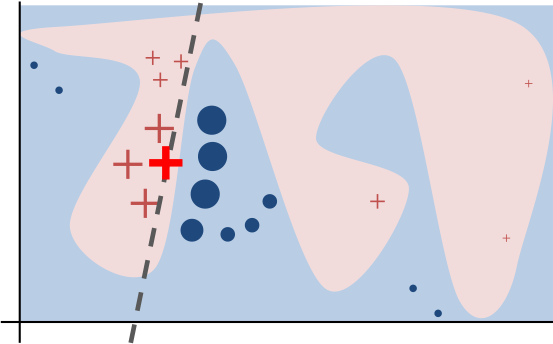

*The intuition behind LIME. Figure from the LIME repository (Ribeiro, Singh & Guestrin, 2016; © 2016 Marco Tulio Ribeiro, BSD licence).*

| In the figure | What it means |
| :--- | :--- |
| blue / pink background | the decision function of the black box $f$: complex, no single line can describe it |
| bold red cross | the instance we want to explain (here: document #532) |
| red crosses and blue dots | **perturbed copies** of the instance, with the class predicted by the black box |
| size of a symbol | its **weight**: copies close to the instance count more |
| dashed line | the **explanation**: a linear model that is faithful **near** the instance, not everywhere |

The Earth is round, but the street in front of your house looks flat: in the same way, around **one** instance a black box can be approximated by a **linear model**, and the coefficients of that linear model are the explanation.

## 2.2 The formula

$$\xi(x) \;=\; \arg\min_{g \in G} \; \mathcal{L}\bigl(f, g, \pi_x\bigr) \;+\; \Omega(g)$$

- $f$: the black box; $x$: the instance to explain; $g \in G$: a simple (linear) model;
- $\mathcal{L}(f, g, \pi_x) = \sum_{z} \pi_x(z)\,\bigl(f(z) - g(z')\bigr)^2$: **local fidelity**, a weighted squared error over perturbed copies $z$ of $x$, where $z'$ is their 0/1 representation (for each word: "kept or removed?");
- $\pi_x(z) = \exp\!\bigl(-D(x,z)^2 / 2\sigma^2\bigr)$: **proximity kernel**, copies similar to $x$ weigh more ($D$ = distance, $\sigma$ = kernel width);
- $\Omega(g)$: **complexity** of $g$ (e.g. number of features used), kept small so that a human can read it.

## 2.3 The recipe in 4 steps (text)

| Step | What LIME does to explain document $x$ |
| :--- | :--- |
| **1. Perturb** | create thousands of **copies** of $x$. For each copy LIME draws **how many** words to remove (a random number between 1 and $d$, the number of distinct words, all equally likely), then **which** ones (at random) |
| **2. Predict** | ask the black box P(oncology) for every copy |
| **3. Weight** | copies with **few words removed** are closer to $x$ and weigh more |
| **4. Fit** | weighted linear regression: "word kept" (1/0) → P(oncology) |

**Are words taken from other documents?** No: a copy can only **lose** words of $x$, it never gains words from other documents (tabular LIME, instead, takes values from other instances of the training data).

**How many words are removed in each copy?** Nobody chooses it: it is **random**, between 1 and $d$, so some copies lose a single word and others almost all of them (about half on average). With `bow=True` (the default), a removed word disappears everywhere it appears in the document.

**What you can set** (in `LimeTextExplainer` and in its method `explain_instance`):

| Parameter | Default | What it controls |
| :--- | :--- | :--- |
| `num_samples` | 5,000 (we use 2,000) | how many copies |
| `kernel_width` | 25 (on a distance from 0 to 100) | how quickly a copy loses weight when more words are removed |
| `bow` | `True` | remove a word everywhere it appears (`True`) or one occurrence at a time (`False`) |
| `num_features` | 10 | how many words the explanation shows |

The **coefficients** of step 4 are the explanation: **+** pushes toward Oncology, **−** toward Cardiology.

## 2.4 🔧 LIME by hand (no library)

We explain document **#532** of the test set. Read it first: which department should it go to?

In [ ]:
# ==========================================
# 4. THE DOCUMENT TO EXPLAIN
# ==========================================

DOC = 532
doc = docs_test[DOC]
p_onc = text_model.predict_proba([doc])[0, 1]           # column 1 = 'oncology'

print(doc)
print(f"\nTrue department: {y_test_txt[DOC].upper()}")
print(f"Model:           P(oncology) = {p_onc:.3f} -> {text_model.predict([doc])[0].upper()} ❌")

In [ ]:
# ==========================================
# 5. LIME BY HAND - STEP 1 (PERTURB) AND STEP 2 (PREDICT)
# ==========================================

tokens = re.findall(r"\w+", doc)              # the words of the document, in order
words = list(dict.fromkeys(tokens))           # the unique words = our interpretable features
d = len(words)
N_SAMPLES = 2000
rng = np.random.RandomState(0)

# Z[i, j] = 1 if word j is KEPT in copy i, 0 if it is REMOVED. Row 0 = the original document.
# For each copy: draw HOW MANY words to remove (1 to d, all equally likely), then WHICH ones (at random)
Z = np.ones((N_SAMPLES, d), dtype=int)
for i in range(1, N_SAMPLES):
    n_removed = rng.randint(1, d + 1)
    Z[i, rng.choice(d, n_removed, replace=False)] = 0

def rebuild(z):
    kept = {w for w, keep in zip(words, z) if keep}
    return " ".join(t for t in tokens if t in kept)

perturbed_docs = [rebuild(z) for z in Z]
p_perturbed = text_model.predict_proba(perturbed_docs)[:, 1]    # STEP 2: ask the black box

removed = d - Z.sum(axis=1)                     # number of words removed, copy by copy
print(f"{d} distinct words -> {N_SAMPLES:,} perturbed copies.")
print(f"Words removed per copy: from {removed[1:].min()} to {removed[1:].max()}, on average {removed[1:].mean():.1f} "
      f"(every number from 1 to {d} is equally likely). Three copies:\n")
for i in [1, 2, 3]:
    print(f"words removed: {removed[i]:2d} | P(oncology) = {p_perturbed[i]:.2f} | {perturbed_docs[i]}")

In [ ]:
# ==========================================
# 6. LIME BY HAND - STEP 3 (WEIGHT) AND STEP 4 (FIT)
# ==========================================

# STEP 3: distance from the original = 1 - cosine similarity of the 0/1 vectors = 1 - sqrt(kept / d)
distance = 1 - np.sqrt(Z.sum(axis=1) / d)              # 0 = identical, 1 = everything removed
KERNEL_WIDTH = 0.25
weights = np.exp(-distance**2 / (2 * KERNEL_WIDTH**2))  # Gaussian kernel pi_x(z)
print("Weight of a copy, by number of words removed:")
print({k: round(float(np.exp(-(1 - np.sqrt((d - k) / d))**2 / (2 * KERNEL_WIDTH**2))), 2) for k in [0, 1, 3, 6, 12, 18, d]}, "\n")

# STEP 4: weighted linear regression   "word kept (0/1)"  ->  P(oncology)
surrogate = Ridge(alpha=1.0).fit(Z, p_perturbed, sample_weight=weights)

lime_by_hand = pd.Series(surrogate.coef_, index=words).sort_values(key=abs, ascending=False)
print("Top-8 words (by hand):   + pushes to ONCOLOGY,  - pushes to CARDIOLOGY\n")
print(lime_by_hand.head(8).round(3).to_string())

In [ ]:
# ==========================================
# 7. WHAT LIME SEES
# ==========================================

with_rome = Z[:, words.index("Rome")] == 1
share_kept = Z.mean(axis=1) + np.random.RandomState(1).uniform(-0.012, 0.012, N_SAMPLES)  # jitter for display

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.scatter(share_kept[with_rome], p_perturbed[with_rome], s=3 + 40 * weights[with_rome],
           color=ORANGE, alpha=0.5, linewidths=0, label="copies WITH 'Rome'")
ax.scatter(share_kept[~with_rome], p_perturbed[~with_rome], s=3 + 40 * weights[~with_rome],
           color=BLUE, alpha=0.5, linewidths=0, label="copies WITHOUT 'Rome'")
ax.axhline(0.5, color=GRAY, lw=1, label="decision threshold")
ax.set_xlabel("share of the original words kept   (bigger dot = closer to the original = more weight)")
ax.set_ylabel("black box: P(oncology)")
ax.set_title(f"What LIME sees: {N_SAMPLES:,} perturbed copies of document #{DOC}", loc="left", pad=26)
ax.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
plt.show()

avg = lambda m: np.average(p_perturbed[m], weights=weights[m])
print(f"Weighted average P(oncology):  copies WITH 'Rome' = {avg(with_rome):.2f}  |  WITHOUT 'Rome' = {avg(~with_rome):.2f}")

### 💡 What did we just see?

The copies that still contain **'Rome'** (orange) are systematically shifted toward Oncology: the weighted linear model turns this gap into a large **positive weight** for 'Rome'. The medical words (*aorta*, *aneurysms*) push the other way, but not enough.

**That is all LIME does**: perturb → predict → weight → fit.

## 2.5 📦 The same with the `lime` library

`LimeTextExplainer` runs the same 4 steps (`bow=True`: a word is removed wherever it appears, consistently with TF-IDF).

In [ ]:
# ==========================================
# 8. LIME WITH THE LIBRARY
# ==========================================

text_explainer = LimeTextExplainer(class_names=list(text_model.classes_), bow=True, random_state=42)
exp_doc = text_explainer.explain_instance(doc, text_model.predict_proba, num_features=8, num_samples=2000)

# Interactive view: predicted probabilities | word weights | highlighted text
show_lime(exp_doc, text=True)

In [ ]:
# ==========================================
# 9. BY HAND vs LIBRARY
# ==========================================

library = pd.Series(dict(exp_doc.as_list()))
comparison = pd.DataFrame({"by hand": lime_by_hand, "lime library": library}).loc[library.index]
print(comparison.round(3), "\n")
print("Small differences come from the random sampling and from the library re-fitting")
print("the linear model on the selected words only. Same method, same verdict.")

exp_doc.as_pyplot_figure().set_size_inches(7, 3.8)
plt.show()

### 💡 From the mechanism to the practice

| Because LIME... | ...it can | ...but |
| :--- | :--- | :--- |
| only needs `predict_proba` on perturbed copies | explain **any** model (forest, network, LLM behind an API) | every explanation costs thousands of model calls |
| removes words | reveal **shortcuts**: if removing "Rome" changes the output, "Rome" matters | perturbed copies can be unnatural texts |
| fits a **linear** model on a **neighbourhood** | give a short, readable list of +/− weights | it is only valid near $x$ and can miss interactions |
| uses **random** sampling | — | results change with `num_samples` and the seed (Part 4) |

# 🐛 Part 3 — Debugging the model with LIME

## 3.1 Is "Rome" a one-off?

One explanation is an anecdote. Let's ask LIME for the **single most important word** of 50 test documents.

In [ ]:
# ==========================================
# 10. THE MOST IMPORTANT WORD OF 50 DOCUMENTS
# ==========================================

top_words = []
for i in range(50):
    e = text_explainer.explain_instance(docs_test[i], text_model.predict_proba, num_features=1, num_samples=1000)
    top_words.append(e.as_list()[0][0].lower())

counts = pd.Series(top_words).value_counts().head(8).sort_values()
is_city = counts.index.isin(["milan", "rome"])

fig, ax = plt.subplots(figsize=(7, 3.4))
bars = ax.barh(counts.index, counts.values, height=0.55, color=np.where(is_city, ORANGE, GRAY))
ax.bar_label(bars, padding=3, color=INK)
ax.set_xlabel("number of documents (out of 50)")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_title("The most important word according to LIME", loc="left")
ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

n_city = int(np.isin(top_words, ["milan", "rome"]).sum())
print(f"👉 In {n_city} of 50 documents the most important 'medical' word is a CITY.")

## 3.2 📅 One year later: the model goes live

After a reorganisation, **both sites treat both conditions**: each department now gets 50% of its documents from each city. Same documents, same model: only the source tags change.

In [ ]:
# ==========================================
# 11. DEPLOYMENT TEST
# ==========================================

docs_deploy = add_source_tag(med_test.medical_abstract, y_test_txt, p_home=0.5, seed=3)
acc_deploy = accuracy_score(y_test_txt, text_model.predict(docs_deploy))

print(f"Test accuracy        (old mix 90/10): {acc_test:.1%}")
print(f"Deployment accuracy  (new mix 50/50): {acc_deploy:.1%}   📉 {100 * (acc_deploy - acc_test):+.1f} points")

### 🐛 The model learned geography, not medicine

The **test set** had the same 90/10 bias as the training set, so it could **not** reveal the problem: the accuracy looked great. **LIME did**, by showing *which words* the model relies on.

## ✍️ Exercise — Fix the text model

1. According to LIME, which words **influence the routing but should not**?
2. Add them to `extra_stop_words` below: the TF-IDF will ignore them.
3. Re-run the two cells and compare **test** and **deployment** accuracy, before and after.

In [ ]:
# ==========================================
# 12. ✍️ EXERCISE: YOUR FIX
# ==========================================

extra_stop_words = []          # 👉 e.g. ['word1', 'word2']

fixed_text_model = train_text_model(docs_train, y_train_txt, extra_stop_words)

In [ ]:
# ==========================================
# 13. BEFORE vs AFTER
# ==========================================

results = pd.DataFrame({
    "Original model": [acc_test, acc_deploy],
    "Fixed model": [accuracy_score(y_test_txt, fixed_text_model.predict(docs_test)),
                    accuracy_score(y_test_txt, fixed_text_model.predict(docs_deploy))]},
    index=["Test (old mix 90/10)", "Deployment (new mix 50/50)"])
dumbbell(results, "accuracy", "Text model: accuracy before and after the fix")
print(f"Extra stop words: {extra_stop_words}")
if not extra_stop_words:
    print("ℹ️ extra_stop_words is empty: the fixed model is identical to the original. Add the confounding words!")

# Document #532 explained again, with the fixed model
show_lime(text_explainer.explain_instance(doc, fixed_text_model.predict_proba,
                                          num_features=8, num_samples=2000), text=True)

<details>
<summary>✅ <b>Solution</b> (click to open)</summary>

```python
extra_stop_words = ['Milan', 'Rome']
```

- The **original** model loses about 9 points in deployment; the **fixed** model has the **same** accuracy on both sets.
- The fixed model has a *lower* test accuracy than the original one: the original was **cheating** with the source tag, and the test set had the same bias, so the cheating paid off there.
- LIME on document #532 now shows only medical words, and the document goes to **Cardiology**.

</details>

# QUESTION: THE FIXED MODEL HAS A LOWER TEST ACCURACY. WOULD YOU DEPLOY IT ANYWAY? HOW WOULD YOU EXPLAIN THIS CHOICE TO YOUR MANAGER?

# ⚠️ Part 4 — The limits of LIME

LIME learns from **random** perturbations: with too few of them, the explanation changes from run to run. Let's explain document #532 three times (3 seeds) with 20 and with 2,000 perturbations.

In [ ]:
# ==========================================
# 14. IS LIME STABLE?
# ==========================================

rows = []
for n in [20, 2000]:
    for seed in [0, 1, 2]:
        e = LimeTextExplainer(class_names=list(text_model.classes_), bow=True, random_state=seed)
        e = e.explain_instance(doc, text_model.predict_proba, num_features=3, num_samples=n)
        rows.append({"num_samples": n, "seed": seed,
                     "top-3 words": ",  ".join(f"{w} ({v:+.2f})" for w, v in e.as_list())})
pd.DataFrame(rows)

With 20 samples the top words change at every run and can even be words like *of* or *the*, which the TF-IDF **ignores** (their weight is pure noise!). With 2,000 samples the explanation is stable.

**The limits of LIME** follow from its mechanism:
- **Instability**: use enough `num_samples` and check with several seeds.
- **Locality**: one explanation = one document; no global view of the model.
- **Approximation**: the linear model may fit the black box poorly; its weights do not add up to the prediction.
- **Unnatural copies**: texts with random words removed are not real documents.

# 📌 Summary

| What LIME revealed | What we did | Result |
| :--- | :--- | :--- |
| The **source city** drives the routing (`Milan`, `Rome`) | Ignore the source words | Same accuracy on the old and on the new hospital mix |

### 🔑 The golden rule

> Accuracy tells you **how often** a model is right. Explanations tell you **why**, and whether it will **still be right tomorrow**.

➡️ **Notebook 4** explains **this same model** with **SHAP**: contributions that **add up exactly** to the prediction, and a **global** view of the whole model.

## 🎯 Final exercises

1. **Probe the model.** Write your own document, e.g. `"[Source: Rome hospital] Chest pain in a 50-year-old patient: a case report."`. Where is it routed? Explain it with LIME, then replace *Rome* with *Milan*. Repeat with a clearly cardiac text (`"... Acute myocardial infarction treated with coronary angioplasty."`): when does the shortcut win?
2. **Kernel width.** In the LIME-by-hand cells, try `KERNEL_WIDTH = 0.1` and `1.0`. How do the weights change, and why? *(Hint: what does a very wide kernel do to the "local" in LIME?)*
3. **Against the shortcut.** Find an Oncology document from **Milan** that the model still routes to Oncology. Which words beat the city?
4. **Longer documents.** In `first_words`, use `n=100` and re-run the notebook. Is the city still the most important word? Is the deployment drop smaller? Why?

---

### References

- Ribeiro, M. T., Singh, S., Guestrin, C. (2016). *"Why Should I Trust You?": Explaining the Predictions of Any Classifier*. KDD 2016.
- Schopf, T., Braun, D., Matthes, F. (2023). *Evaluating Unsupervised Text Classification: Zero-Shot and Similarity-Based Approaches*. NLPIR 2022 (Medical Abstracts dataset).
- Zech, J. R. et al. (2018). *Variable generalization performance of a deep learning model to detect pneumonia in chest radiographs: A cross-sectional study*. PLOS Medicine, 15(11).
- LIME library: <https://github.com/marcotcr/lime>